# Neural Network Fundamentals: Forward Pass and Backpropagation

> Connect familiar ML ideas to neurons, activations, loss functions, and gradient-based learning.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Compute a neuron output and a tiny network forward pass.
- Understand parameters, activation functions, loss, and gradients.
- Fit a small MLP using scikit-learn to connect theory to practice.

This is an introductory bridge—not a complete deep learning course. The key idea is that a network is a composition of differentiable functions; training adjusts weights to reduce a loss.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -40, 40)))

x = np.array([1.2, -0.7, 0.3])
w = np.array([0.5, -0.2, 0.8])
b = -0.1
z = w @ x + b
y_hat = sigmoid(z)
print("Linear combination z:", round(z,3))
print("Neuron output:", round(y_hat,3))

Linear combination z: 0.88
Neuron output: 0.707


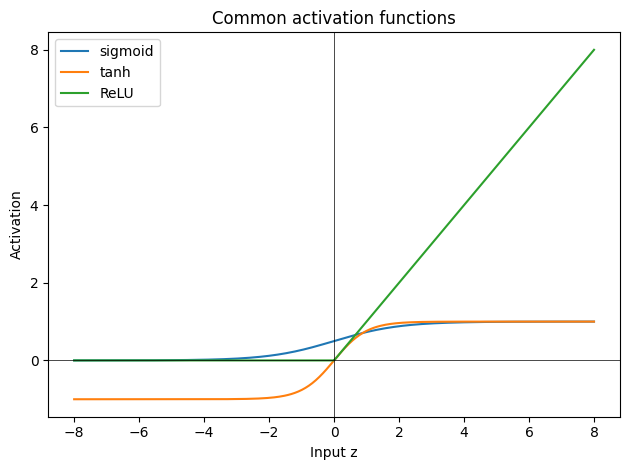

In [2]:
z = np.linspace(-8, 8, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, np.tanh(z), label="tanh")
plt.plot(z, np.maximum(0, z), label="ReLU")
plt.axhline(0, color="black", linewidth=.5)
plt.axvline(0, color="black", linewidth=.5)
plt.legend()
plt.title("Common activation functions")
plt.xlabel("Input z")
plt.ylabel("Activation")
plt.tight_layout()

## Finite-difference gradient intuition
The derivative tells how a small parameter change alters the loss. In a deep network, the chain rule applies repeatedly; backpropagation efficiently computes these gradients by reusing intermediate derivatives.

In [3]:
# A tiny one-parameter model: y_hat = w*x, with mean squared error.
x = np.array([1., 2., 3.])
y = np.array([2., 4., 5.])
def loss(w): return np.mean((w*x-y)**2)
w0 = 1.2
eps = 1e-5
finite_difference = (loss(w0+eps)-loss(w0-eps))/(2*eps)
analytic = np.mean(2*(w0*x-y)*x)
print("Finite-difference gradient:", round(finite_difference,6))
print("Analytical gradient:", round(analytic,6))

Finite-difference gradient: -5.466667
Analytical gradient: -5.466667


Test accuracy: 0.88


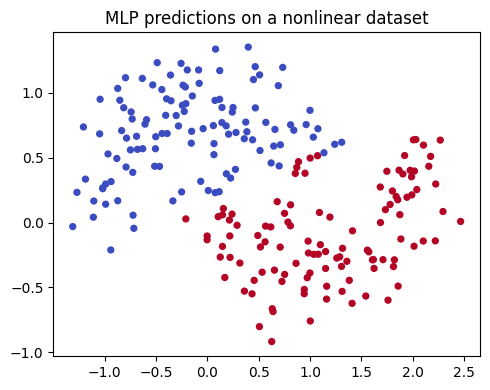

In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
X, y = make_moons(n_samples=900, noise=.22, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=700, early_stopping=True, random_state=42))
mlp.fit(X_train, y_train)
print("Test accuracy:", round(accuracy_score(y_test, mlp.predict(X_test)),3))
plt.figure(figsize=(5,4)); plt.scatter(X_test[:,0], X_test[:,1], c=mlp.predict(X_test), s=18, cmap="coolwarm"); plt.title("MLP predictions on a nonlinear dataset"); plt.tight_layout()

## What to remember
- Forward propagation computes predictions from inputs and current weights.
- A loss converts predictions and targets into a scalar training objective.
- Backpropagation computes gradients; an optimizer updates parameters.
- More layers and parameters increase representation capacity but can also increase data and compute needs.
- Validation, regularization, early stopping, and careful preprocessing remain important.

## Practice
Change the hidden-layer sizes or add `alpha` regularization. Record both training and test performance, and describe what would make you suspect overfitting.